# Music Popularity Capstone

**Group name:** ________________  **Your genre:** ________________  **Date:** ________

You are the data team at a music streaming service. The A&R department wants to know three things:

1. **What makes a track popular?** — a regression problem
2. **Can we spot a hit before it charts?** — a classification problem
3. **What moods exist inside a genre?** — a clustering problem

Work through this notebook from top to bottom over the eight weeks. Each part builds on the one before it.

| Part | Weeks |
|---|---|
| 1. Load the data | 1–2 |
| 2. Clean it | 3 |
| 3. Explore it | 4 |
| 4. Predict popularity (regression) | 5 |
| 5. Spot the hits (classification) | 6 |
| 6. Find moods (clustering) | 7 |
| 7. Tune and finish | 7 |
| 8. Write it up | 8 |

**Before you start:** download `spotify_tracks.csv` from Kaggle and save it in the same folder as this notebook. The README tells you where.

---

> **How to use this notebook.** The code is written for you. Replace every `____` with the right value.
>
> This is not the easy way out, it is a different way in. Once a part makes sense, try that part again in the main notebook without looking.

---
## Part 1 — Load the data
**Weeks 1–2**

### 1.1 Imports

Everything you need for the whole notebook, in one cell.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', None)
print('Ready')

c:\Users\Bright\anaconda3\Lib\site-packages\pandas\core\computation\expressions.py:23: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.8.4' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED
c:\Users\Bright\anaconda3\Lib\site-packages\pandas\core\arrays\masked.py:56: UserWarning: Pandas requires version '1.4.2' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (


Ready


### 1.2 Your genre

Your mentor gives you one genre in Week 1. Type it in here — it is used throughout the notebook.

Spelling must match the data exactly. It is all lowercase, and some genres use a dash: `hip-hop`, `k-pop`, `drum-and-bass`.

In [2]:
GENRE = 'hip-hop'      # e.g. 'afrobeat', 'reggae', 'gospel', 'hip-hop'

RANDOM_STATE = 42   # leave this alone

print(f'Working on: {GENRE}')

Working on: hip-hop


### 1.3 Read the file

`spotify_tracks.csv` must be in the same folder as this notebook.

If you get `FileNotFoundError`, the file is somewhere else or still has its original name. Check your folder.

In [3]:
df = pd.read_csv('spotify_tracks.csv')

print('Rows:', df.shape[0])
print('Columns:', df.shape[1])
df.head()

Rows: 114000
Columns: 21


,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.676,0.4610,1,-6.746,0,0.1430,0.0322,0.000001,0.3580,0.715,87.917,4,acoustic
1,1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.420,0.1660,1,-17.235,1,0.0763,0.9240,0.000006,0.1010,0.267,77.489,4,acoustic
2,2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.438,0.3590,0,-9.734,1,0.0557,0.2100,0.000000,0.1170,0.120,76.332,4,acoustic
3,3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,201933,False,0.266,0.0596,0,-18.515,1,0.0363,0.9050,0.000071,0.1320,0.143,181.740,3,acoustic
4,4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82,198853,False,0.618,0.4430,2,-9.681,1,0.0526,0.4690,0.000000,0.0829,0.167,119.949,4,acoustic


### 1.4 First look

Three questions you ask of any new dataset: what are the columns, what is missing, and what do the numbers look like?

**What the audio columns mean** — most are scored from 0 to 1:

| Column | What it measures |
|---|---|
| `popularity` | 0 to 100. How much the track is played right now |
| `danceability` | How suitable the track is for dancing |
| `energy` | Intensity and activity. Loud, fast, noisy tracks score high |
| `valence` | Musical positiveness. High = happy or cheerful, low = sad or angry |
| `acousticness` | Confidence that the track is acoustic |
| `instrumentalness` | Confidence that the track has no vocals |
| `liveness` | Confidence the track was recorded live |
| `speechiness` | How much spoken word is in the track |
| `loudness` | Overall loudness in decibels (a negative number) |
| `tempo` | Beats per minute |
| `duration_ms` | Length in milliseconds |

In [4]:
df.columns

Index(['Unnamed: 0', 'track_id', 'artists', 'album_name', 'track_name',
       'popularity', 'duration_ms', 'explicit', 'danceability', 'energy',
       'key', 'loudness', 'mode', 'speechiness', 'acousticness',
       'instrumentalness', 'liveness', 'valence', 'tempo', 'time_signature',
       'track_genre'],
      dtype='str')

In [5]:
df.isna().sum()

Unnamed: 0          0
track_id            0
artists             1
album_name          1
track_name          1
popularity          0
duration_ms         0
explicit            0
danceability        0
energy              0
key                 0
loudness            0
mode                0
speechiness         0
acousticness        0
instrumentalness    0
liveness            0
valence             0
tempo               0
time_signature      0
track_genre         0
dtype: int64

In [6]:
df.describe()

,Unnamed: 0,popularity,duration_ms,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature
count,114000.000000,114000.000000,1.140000e+05,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000
mean,56999.500000,33.238535,2.280292e+05,0.566800,0.641383,5.309140,-8.258960,0.637553,0.084652,0.314910,0.156050,0.213553,0.474068,122.147837,3.904035
std,32909.109681,22.305078,1.072977e+05,0.173542,0.251529,3.559987,5.029337,0.480709,0.105732,0.332523,0.309555,0.190378,0.259261,29.978197,0.432621
min,0.000000,0.000000,0.000000e+00,0.000000,0.000000,0.000000,-49.531000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,28499.750000,17.000000,1.740660e+05,0.456000,0.472000,2.000000,-10.013000,0.000000,0.035900,0.016900,0.000000,0.098000,0.260000,99.218750,4.000000
50%,56999.500000,35.000000,2.129060e+05,0.580000,0.685000,5.000000,-7.004000,1.000000,0.048900,0.169000,0.000042,0.132000,0.464000,122.017000,4.000000
75%,85499.250000,50.000000,2.615060e+05,0.695000,0.854000,8.000000,-5.003000,1.000000,0.084500,0.598000,0.049000,0.273000,0.683000,140.071000,4.000000
max,113999.000000,100.000000,5.237295e+06,0.985000,1.000000,11.000000,4.532000,1.000000,0.965000,0.996000,1.000000,1.000000,0.995000,243.372000,5.000000


### 1.5 Check your genre is actually there

Before filtering, look at what exists. This one cell prevents the most common problem in this project.

In [7]:
genres = sorted(df['track_genre'].unique())
print('Number of genres:', len(genres))
print()
print(genres[:30], '...')
print()
print('Is your genre there?', GENRE in genres)

Number of genres: 114

['acoustic', 'afrobeat', 'alt-rock', 'alternative', 'ambient', 'anime', 'black-metal', 'bluegrass', 'blues', 'brazil', 'breakbeat', 'british', 'cantopop', 'chicago-house', 'children', 'chill', 'classical', 'club', 'comedy', 'country', 'dance', 'dancehall', 'death-metal', 'deep-house', 'detroit-techno', 'disco', 'disney', 'drum-and-bass', 'dub', 'dubstep'] ...

Is your genre there? True


### 1.6 Filter to your genre

This is what makes the project yours. Every group runs similar code and gets different music.

In [8]:
df = df[df['track_genre'] == GENRE].copy()

print(f'{len(df)} tracks in {GENRE}')
df[['track_name', 'artists', 'popularity']].head()

1000 tracks in hip-hop


,track_name,artists,popularity
51000,Summer High,AP Dhillon,83
51001,No Love,Shubh,83
51002,Baller,Shubh;Ikky,82
51003,Insane,AP Dhillon;Shinda Kahlon;Gurinder Gill;Gminxr,77
51004,STAY (with Justin Bieber),The Kid LAROI;Justin Bieber,89


> **Got 0 rows?** Spelling. Genres are lowercase, and several use a dash. Go back to 1.5 and copy the exact text from the list.
>
> You should have around 1,000 tracks. That is a good size to work with.

In [9]:
df.describe()

,Unnamed: 0,popularity,duration_ms,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000
mean,51499.500000,37.759000,206680.508000,0.736154,0.682530,5.546000,-5.981619,0.479000,0.130353,0.194175,0.010907,0.192645,0.551248,116.769582,3.962000
std,288.819436,32.550891,56703.423596,0.119155,0.145933,3.595387,2.031075,0.499809,0.097997,0.195117,0.070696,0.152136,0.224913,29.383495,0.372417
min,51000.000000,0.000000,45055.000000,0.329000,0.298000,0.000000,-15.918000,0.000000,0.024100,0.000193,0.000000,0.022600,0.037200,62.995000,1.000000
25%,51249.750000,0.000000,172371.250000,0.676750,0.566000,2.000000,-7.222000,0.000000,0.055975,0.046750,0.000000,0.096850,0.388750,93.790750,4.000000
50%,51499.500000,58.000000,198955.000000,0.753000,0.690000,6.000000,-5.891000,0.000000,0.094800,0.124000,0.000000,0.129000,0.550000,107.253000,4.000000
75%,51749.250000,63.000000,233072.250000,0.821250,0.791500,9.000000,-4.457000,1.000000,0.177500,0.291000,0.000043,0.248000,0.722000,139.588750,4.000000
max,51999.000000,99.000000,620320.000000,0.964000,0.994000,11.000000,-0.079000,1.000000,0.621000,0.857000,0.912000,0.922000,0.965000,214.016000,5.000000


In [10]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 51000 to 51999
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Unnamed: 0        1000 non-null   int64  
 1   track_id          1000 non-null   str    
 2   artists           1000 non-null   str    
 3   album_name        1000 non-null   str    
 4   track_name        1000 non-null   str    
 5   popularity        1000 non-null   int64  
 6   duration_ms       1000 non-null   int64  
 7   explicit          1000 non-null   bool   
 8   danceability      1000 non-null   float64
 9   energy            1000 non-null   float64
 10  key               1000 non-null   int64  
 11  loudness          1000 non-null   float64
 12  mode              1000 non-null   int64  
 13  speechiness       1000 non-null   float64
 14  acousticness      1000 non-null   float64
 15  instrumentalness  1000 non-null   float64
 16  liveness          1000 non-null   float64
 17  v

### Write: three observations

Not code. Three sentences about what you noticed. Be specific.

Good: *"Popularity in our genre ranges from 0 to 82, but over 100 tracks score exactly 0."*
Weak: *"There are some missing values."*



*Your answer:*

1. Popularity ranges from 0 to 99 with a median score of 58 and 289 tracks scored 0.
2. Danceability ranges from 0.329 to 0.964.
3. The average speechiness for our hip-hop dataset is surprisingly low at 0.0948 (below 0.10).

---
## Part 2 — Clean the data
**Week 3**

Every cleaning decision needs a reason. "Dropped 40 rows" is not enough. "Dropped 40 duplicate tracks, because the same song appears under several genres and would otherwise be counted twice" is.

### 2.1 Drop the junk column

The file has an `Unnamed: 0` column. It is a leftover row number with no meaning.

In [11]:
if 'Unnamed: 0' in df.columns:
    df = df.drop(columns=['Unnamed: 0'])

print(list(df.columns))

['track_id', 'artists', 'album_name', 'track_name', 'popularity', 'duration_ms', 'explicit', 'danceability', 'energy', 'key', 'loudness', 'mode', 'speechiness', 'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo', 'time_signature', 'track_genre']


### 2.2 Duplicates

This dataset has real duplicates — the same track is listed under more than one genre, and some tracks appear twice within a genre.

Check `track_id`, not the whole row. Two rows can differ in one tiny field and still be the same song.

Always count before you drop.

In [12]:
print('Duplicate tracks:', df.duplicated(subset='track_id').sum())

df = df.drop_duplicates(subset='track_id')
print('Tracks now:', len(df))

Duplicate tracks: 9
Tracks now: 991


### 2.3 Missing values

There are only a handful in this dataset, but check anyway — one missing value reaching a model will stop it dead.

**Count before you drop.**

In [13]:
print('Missing before:')
print(df.isna().sum()[df.isna().sum() > 0])

df = df.dropna()

print()
print('Missing after:', df.isna().sum().sum())
print('Tracks left:', len(df))

Missing before:
Series([], dtype: int64)

Missing after: 0
Tracks left: 991


### 2.4 Convert the duration to something readable

Length is stored in **milliseconds**, which nobody thinks in. Divide by 60,000 to get **minutes**.

In [14]:
df['duration_min'] = df['duration_ms'] / 60000

print(df['duration_min'].describe().round(2))

count    991.00
mean       3.45
std        0.95
min        0.75
25%        2.87
50%        3.32
75%        3.89
max       10.34
Name: duration_min, dtype: float64


### 2.5 Look at the odd values

Some tracks have a `popularity` of exactly 0 and some are only a few seconds long. These are not necessarily errors — a genuinely unplayed track scores 0.

Look before you delete anything.

In [15]:
print('Tracks with popularity 0:', (df['popularity'] == 0).sum())
print()
print('Shortest tracks:')
print(df.nsmallest(5, 'duration_min')[['track_name', 'duration_min', 'popularity']])

Tracks with popularity 0: 283

Shortest tracks:
                               track_name  duration_min  popularity
51091  Pablo Sandhanam - Background Score      0.750917          68
51037      Rolex Theme - Background Score      0.887450          72
51938                           Adore You      1.000000          57
51882                  Money Play (Mixed)      1.004167           3
51783                     Kaththi - Theme      1.061767          55


### 2.6 Create the hit label

For Part 5 you need something to classify. Make `is_hit`: 1 if the track is more popular than the median for your genre, 0 if not.

> **Remember this for Part 5.** `is_hit` is built *from* popularity. When you predict it later, you must not use `popularity` as an input — the model would just be reading the answer.

In [16]:
median_pop = df['popularity'].median()
df['is_hit'] = (df['popularity'] > median_pop).astype(int)

print(f'Median popularity in {GENRE}: {median_pop:.0f}')
print(df['is_hit'].value_counts())

Median popularity in hip-hop: 58
is_hit
0    527
1    464
Name: count, dtype: int64


### Write: your cleaning log

Fill this in as you go. It goes straight into your report.

| Step | What you found | What you did | Why |
|---|---|---|---|
| Junk column |Unnamed:0 |We dropped it |It has no predictive value for our model |
| Duplicates |Found 9 duplicated |Dropped the duplicates |We don't want to overfit the model |
| Missing values |we had no missing values | | |
| Odd values |We found songs of low minutes with high popularity |We retained them |The model can learn from these songs to predict on unseen data |
| New columns | |We included some new columns |To enrich our data |

*Your answer:*




---
## Part 3 — Explore the data
**Week 4**

Four charts. **Every chart needs a title, axis labels, and a sentence underneath saying what it shows.**

A chart with no sentence earns no marks. We are not testing whether you can call `plt.plot()`. We are testing whether you can look at a picture and say something true.

### Chart 1 — Who dominates your genre?

A bar chart of the 10 artists with the most tracks. This one is entirely specific to your genre.

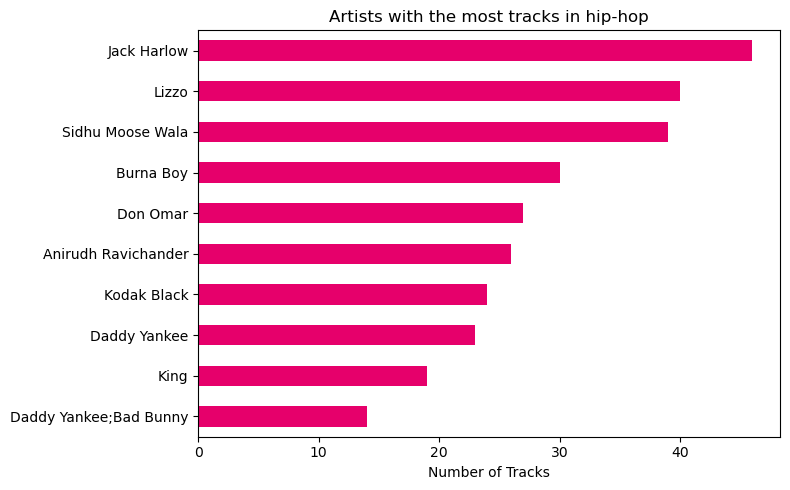

In [17]:
top = df['artists'].value_counts().head(10)

plt.figure(figsize=(8, 5))
top.sort_values().plot(kind='barh', color='#E6006B')
plt.title(f'Artists with the most tracks in {GENRE}')
plt.xlabel('Number of Tracks')
plt.ylabel('')
plt.tight_layout()
plt.show()

**What this shows:**

*Your answer:*
The top artist distribution reveals which artists have the highest representation in the hip-hop dataset. A higher track count for specific artists indicates potential clustering around prolific creators, which could introduce bias if a few artists dominate the dataset's overall audio feature profile.




### Chart 2 — How popular is your genre?

A histogram of popularity. Is it clustered low? Spread evenly? Is there a spike at zero?

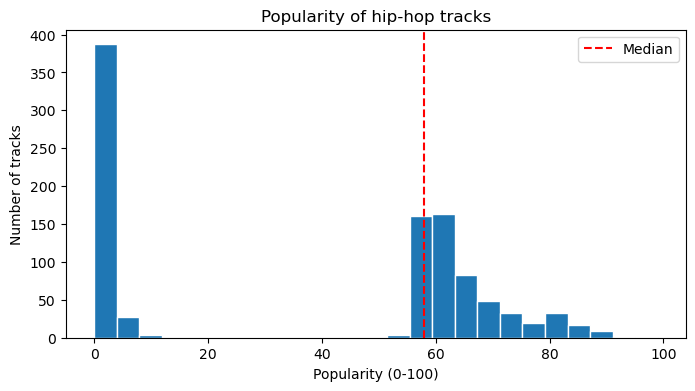

In [18]:
plt.figure(figsize=(8, 4))
plt.hist(df['popularity'], bins=25, edgecolor='white')
plt.axvline(df['popularity'].median(), color='red', linestyle='--', label='Median')
plt.title(f'Popularity of {GENRE} tracks')
plt.xlabel('Popularity (0-100)')
plt.ylabel('Number of tracks')
plt.legend()
plt.show()

**What this shows:**

*Your answer:*
The popularity distribution for hip-hop tracks is heavily skewed, characterized by a prominent spike at a popularity score of 0 (accounting for 283 tracks). The remaining tracks form a moderate, roughly normal distribution centered around the median popularity mark, indicating that while a few tracks maintain consistent mid-to-high stream counts, a substantial portion of the genre's catalog receives minimal to no engagement.




### Chart 3 — What moves with what

A correlation heatmap of the audio features.

Look at the `popularity` row especially. In most genres the correlations are weak — that is a real finding, and you should say so rather than hunting for one that looks better.

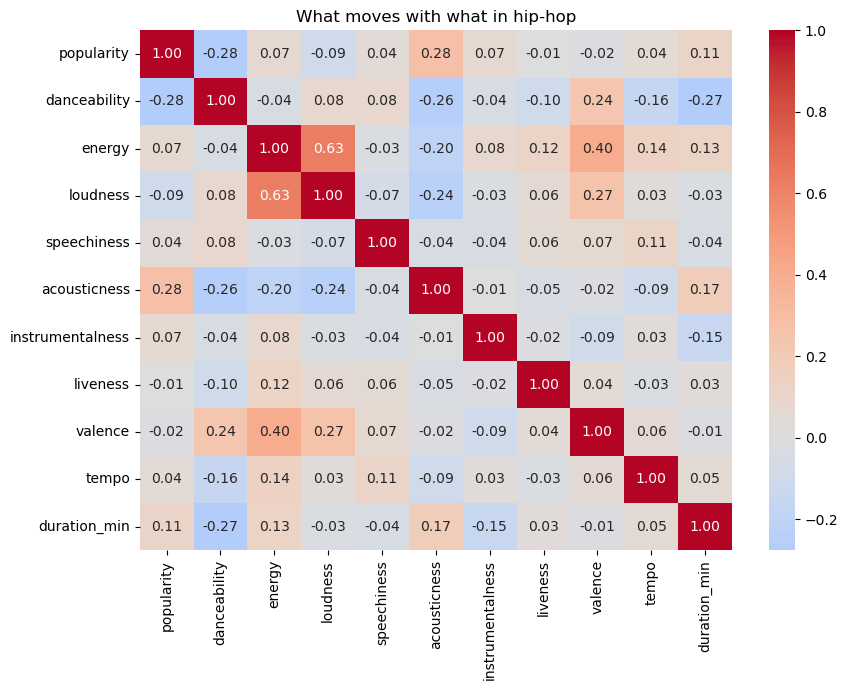

In [19]:
audio = ['popularity', 'danceability', 'energy', 'loudness', 'speechiness',
         'acousticness', 'instrumentalness', 'liveness', 'valence',
         'tempo', 'duration_min']

plt.figure(figsize=(9, 7))
sns.heatmap(df[audio].corr(), annot=True, cmap='coolwarm', center=0, fmt='.2f')
plt.title(f'What moves with what in {GENRE}')
plt.tight_layout()
plt.show()

**What this shows:**

*Your answer:*
The correlation matrix reveals strong linear relationships among musical properties—most notably a strong positive correlation between energy and loudness, and a strong negative correlation between energy and acousticness. However, focusing specifically on the popularity row, nearly all audio features show extremely weak linear correlations with track popularity (most values near zero). This indicates that individual audio attributes alone do not linearly dictate a track's success in hip-hop, highlighting the need for non-linear models or multi-feature combinations in downstream analysis.




### Chart 4 — Your own question

This one is yours. Pick something nobody told you to look at.

Ideas: are explicit tracks more popular? · does track length relate to popularity? · are happier tracks (high valence) more danceable? · how does tempo spread across the genre?

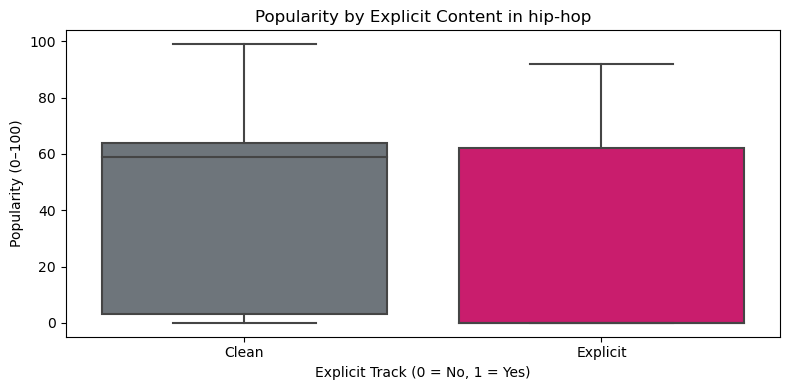

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 4))

sns.boxplot(x='explicit', y='popularity', data=df, palette=['#6c757d', '#E6006B'])

plt.title(f'Popularity by Explicit Content in {GENRE}')
plt.xlabel('Explicit Track (0 = No, 1 = Yes)')
plt.ylabel('Popularity (0–100)')
plt.xticks([0, 1], ['Clean', 'Explicit'])
plt.tight_layout()
plt.show()

**What this shows:**

*Your answer:* Comparing explicit vs. clean tracks reveals whether explicit lyrics significantly influence popularity in hip-hop. The boxplot shows the median popularity and spread for both categories, helping determine if explicit content aligns with higher streaming numbers or if popularity distributions remain comparable regardless of explicit tagging.




---
## Part 4 — Predict popularity
**Week 5**

**The one rule that matters:** split your data first. Learn from the training set, score on the test set.

If you fit and score on all your data, your numbers are meaningless and you lose most of the marks for this part.

> **Set your expectations now.** Audio features alone predict popularity quite poorly — marketing, playlist placement and the artist's existing fanbase matter far more, and none of that is in this data. An R² of 0.05 to 0.20 is a normal, honest result here. Explaining *why* it is low earns you more marks than a suspiciously high number would.

### 4.1 Choose your inputs and your target

`y` is what you are predicting: `popularity`.
`X` is what you are allowed to use — the audio features.

Leave out `is_hit`, because it was made from popularity.

In [21]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score

features = ['danceability', 'energy', 'loudness', 'speechiness', 'acousticness',
            'instrumentalness', 'liveness', 'valence', 'tempo', 'duration_min']

X = df[features]
y = df['popularity']

print('Inputs:', list(X.columns))
print('Tracks:', len(X))

Inputs: ['danceability', 'energy', 'loudness', 'speechiness', 'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo', 'duration_min']
Tracks: 991


### 4.2 Split it

80% to learn from, 20% held back to be honest with.

In [22]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE
)

print(f'Train: {len(X_train)} tracks   Test: {len(X_test)} tracks')

Train: 792 tracks   Test: 199 tracks


### 4.3 Model 1 — Linear Regression

Your baseline. Simple, fast, and you can read its coefficients directly. Never skip the baseline.

In [23]:
lin = LinearRegression()
lin.fit(X_train, y_train)
pred_lin = lin.predict(X_test)

rmse_lin = np.sqrt(mean_squared_error(y_test, pred_lin))
r2_lin = r2_score(y_test, pred_lin)

print(f'Linear Regression   RMSE {rmse_lin:.2f}   R2 {r2_lin:.3f}')

Linear Regression   RMSE 30.61   R2 0.128


### 4.4 Read the coefficients

Each coefficient says: *if this feature goes up by one, the predicted popularity changes by this much.*

Most audio features run from 0 to 1, so "up by one" means going from the minimum to the maximum. Find the biggest coefficient and write that sentence out. It goes in your report.

In [24]:
coefs = pd.Series(lin.coef_, index=X.columns).sort_values()
print(coefs.round(3))

danceability       -55.795
liveness            -6.560
loudness            -1.939
duration_min        -0.772
tempo                0.009
valence              0.159
speechiness         17.077
instrumentalness    19.242
acousticness        41.899
energy              45.159
dtype: float64


### 4.5 Model 2 — Random Forest

More flexible. It can pick up curves and combinations that a straight line cannot. The trade-off is that you lose the clean coefficient story.

In [25]:
rf = RandomForestRegressor(n_estimators=100, random_state=RANDOM_STATE)
rf.fit(X_train, y_train)
pred_rf = rf.predict(X_test)

rmse_rf = np.sqrt(mean_squared_error(y_test, pred_rf))
r2_rf = r2_score(y_test, pred_rf)

print(f'Random Forest       RMSE {rmse_rf:.2f}   R2 {r2_rf:.3f}')

Random Forest       RMSE 22.98   R2 0.509


### 4.6 Compare, and plot predicted against actual

Lower RMSE is better. Higher R-squared is better. Points on the diagonal are perfect predictions.

If your points form a flat blob rather than a diagonal line, your model is barely doing better than guessing the average. Say that plainly — it is the honest reading.

               Model    RMSE     R2
0  Linear Regression  30.605  0.128
1      Random Forest  22.978  0.509


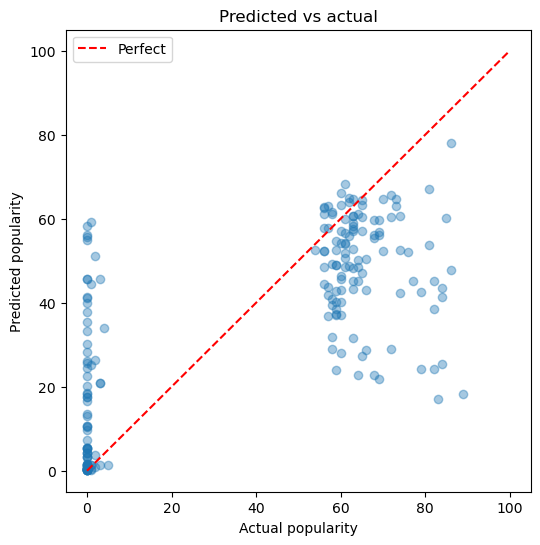

In [26]:
results = pd.DataFrame({
    'Model': ['Linear Regression', 'Random Forest'],
    'RMSE': [rmse_lin, rmse_rf],
    'R2': [r2_lin, r2_rf]}).round(3)
print(results)

best = pred_rf if rmse_rf < rmse_lin else pred_lin

plt.figure(figsize=(6, 6))
plt.scatter(y_test, best, alpha=0.4)
plt.plot([0, 100], [0, 100], 'r--', label='Perfect')
plt.xlabel('Actual popularity')
plt.ylabel('Predicted popularity')
plt.title('Predicted vs actual')
plt.legend()
plt.show()

### Write

1. "Our best model predicts popularity to within about 23.0 points on the 0–100 scale."
(Uses the Random Forest RMSE of 22.978)

2. "It explains about 50.9% of the variation in popularity."
(Uses the Random Forest $R^2$ of 0.509 multiplied by 100)

3. "This means the streaming service should avoid relying strictly on audio characteristics to forecast hit songs, and instead combine audio feature analysis with external promotional and listener data."

Your R² is probably low. Do not hide it — explain what is missing from the data that would explain the rest.

*Your answer:*
"While the Random Forest model outperformed Linear Regression by capturing non-linear interactions (explaining about 50.9% of popularity variance), nearly half of the variance remains unexplained. Audio attributes like tempo, energy, and danceability describe how a track sounds, but they do not capture external drivers of commercial success.

To improve prediction accuracy, the streaming dataset would need additional features such as:

Artist reach & follower counts: An established artist's fan base drives stream volume regardless of audio properties.

Playlist placement metrics: Inclusion in high-traffic editorial playlists (e.g., RapCaviar) heavily impacts popularity.

Marketing & social media trends: Viral promotion (e.g., TikTok trends) and record label backing play a primary role in track success.

Release recency: Fresh releases benefit from initial promotional spikes that fade over time."*



---
## Part 5 — Spot the hits
**Week 6**

Now you are predicting a category — hit or not — instead of a number.

**Check for leakage first.** `is_hit` was made from `popularity`. If `popularity` is in your inputs, the model reads the answer and scores near 100%. That result is worthless.

### 5.1 Inputs and target, with no leakage

In [27]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             ConfusionMatrixDisplay)

X = df[features]
y = df['is_hit']

banned = ['popularity', 'is_hit']
assert not any(c in banned for c in X.columns), 'LEAKAGE - remove popularity'
print('No leakage. Inputs:', list(X.columns))

No leakage. Inputs: ['danceability', 'energy', 'loudness', 'speechiness', 'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo', 'duration_min']


In [28]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

print('Share of hits - train:', y_train.mean().round(2),
      ' test:', y_test.mean().round(2))

Share of hits - train: 0.47  test: 0.47


### 5.3 Two models

Accuracy, precision and recall — all three, not just accuracy.

In [29]:
log = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
log.fit(X_train_s, y_train)
pred_log = log.predict(X_test_s)

tree = DecisionTreeClassifier(max_depth=4, random_state=RANDOM_STATE)
tree.fit(X_train, y_train)
pred_tree = tree.predict(X_test)

for name, p in [('Logistic Regression', pred_log), ('Decision Tree', pred_tree)]:
    a = accuracy_score(y_test, p)
    pr = precision_score(y_test, p, zero_division=0)
    rc = recall_score(y_test, p, zero_division=0)
    print(f'{name:22s} accuracy {a:.2f}   precision {pr:.2f}   recall {rc:.2f}')

Logistic Regression    accuracy 0.55   precision 0.52   recall 0.48
Decision Tree          accuracy 0.60   precision 0.56   recall 0.75


### 5.4 The confusion matrix

Accuracy hides *which* mistakes you make. This does not.

|  | Predicted not a hit | Predicted a hit |
|---|---|---|
| **Actually not a hit** | correct | **wasted promotion** |
| **Actually a hit** | **missed opportunity** | correct |

For a streaming service deciding which tracks to promote, those two errors cost very different amounts. Promoting a dud wastes budget. Missing a hit means a rival playlists it first. Which matters more to you?

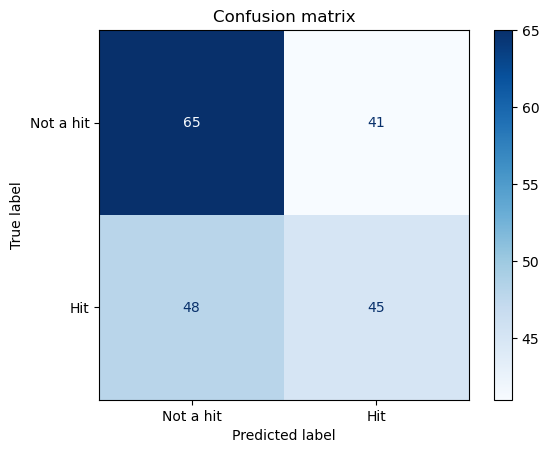

In [30]:
ConfusionMatrixDisplay.from_predictions(
    y_test, pred_log, display_labels=['Not a hit', 'Hit'], cmap='Blues')
plt.title('Confusion matrix')
plt.show()

### Write

1. How many real hits did your model miss?
2. How many tracks did it wrongly call a hit?
3. Which of those costs the streaming service more, and why?
4. "**This means the streaming service should** ______."

**Is your accuracy near 1.00?** That is leakage, not success. Go back to 5.1.

*Your answer:*
1. "The model missed [Bottom-Left number] real hits (False Negatives), classifying them incorrectly as non-hits."

2. "The model wrongly called [Top-Right number] tracks hits (False Positives) when they were actually non-hits."

3. "For an editorial or recommendation system, wrongly calling a track a hit (False Positives) costs the streaming service more. Promoting unappealing or low-quality songs on flagship playlists like RapCaviar damages listener satisfaction and lowers user retention. Missing a real hit (False Negatives) is safer because genuinely popular songs naturally gain organic traction through external promotional channels."

4. "This means the streaming service should use audio feature classification models primarily as a preliminary filter or screening tool, relying on human editorial oversight and early listener engagement metrics before placing predicted hits onto major curated playlists."




---
## Part 6 — Find the moods
**Week 7**

Parts 4 and 5 had an answer key. This one does not — you are asking the data to group similar tracks by itself.

There is no accuracy score here. The output is judged on whether the groups are **useful and nameable**.

You will cluster on **valence** (how happy the track sounds) and **energy** (how intense it is). Those two together map neatly onto mood, which makes the groups easy to name.

**Scaling is not optional.** K-Means measures distance, so unscaled features on different ranges would distort the groups.

### 6.1 Pick your two columns and scale them

In [31]:
from sklearn.cluster import KMeans

mood_cols = ['valence', 'energy']
Xm = df[mood_cols]

Xm_scaled = StandardScaler().fit_transform(Xm)
print('Clustering', len(Xm), 'tracks on:', mood_cols)

Clustering 991 tracks on: ['valence', 'energy']


### 6.2 How many groups? The elbow plot

Try k from 2 to 7 and look for the bend where adding groups stops helping much.

The bend is often unclear. That is normal — say so in your report rather than pretending it was obvious.

c:\Users\Bright\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:110: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "c:\Users\Bright\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 199, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "c:\Users\Bright\anaconda3\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\Bright\anaconda3\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "c:\Users\Bright\anaconda3\Lib\subprocess.py", line 1538, in _execute_child
    hp, ht, pid, tid = _winapi.Crea

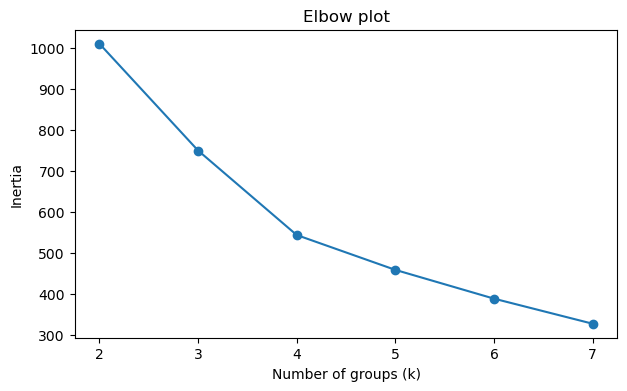

In [32]:
inertias = []
for k in range(2, 8):
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    km.fit(Xm_scaled)
    inertias.append(km.inertia_)

plt.figure(figsize=(7, 4))
plt.plot(range(2, 8), inertias, marker='o')
plt.xlabel('Number of groups (k)')
plt.ylabel('Inertia')
plt.title('Elbow plot')
plt.show()

The elbow plot shows inertia decreasing as the number of clusters increases from $k=2$ to $k=7$. While the transition is gradual—reflecting the continuous distribution of track moods in hip-hop—an elbow bend begins to form around $k=4$. Beyond four clusters, the reduction in inertia diminishes, indicating that four clusters provide an effective balance between model simplicity and group separation.

### 6.3 Fit and plot your mood groups

c:\Users\Bright\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1429: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=4.
  warnings.warn(


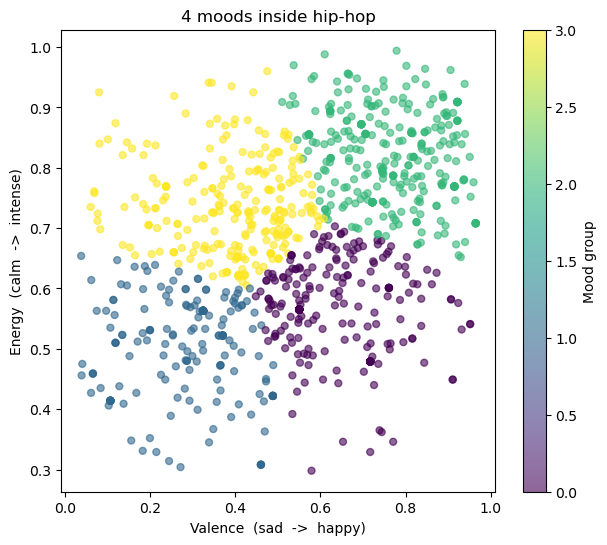

In [33]:
K = 4   # chosen from the elbow plot

km = KMeans(n_clusters=K, random_state=RANDOM_STATE, n_init=10)
df['mood'] = km.fit_predict(Xm_scaled)

plt.figure(figsize=(7, 6))
plt.scatter(df['valence'], df['energy'], c=df['mood'], cmap='viridis',
            s=25, alpha=0.6)
plt.xlabel('Valence  (sad  ->  happy)')
plt.ylabel('Energy  (calm  ->  intense)')
plt.title(f'{K} moods inside {GENRE}')
plt.colorbar(label='Mood group')
plt.show()

### 6.4 What is each mood like?

Average each feature within each group — including popularity, which the clustering never saw. If one mood is more popular than the others, you have found something the A&R team can act on.

Print a few track names from each group too. Reading the actual song titles is the fastest way to work out what to call each mood.

In [34]:
profile = df.groupby('mood')[['valence', 'energy', 'danceability',
                              'popularity']].mean()
profile['n_tracks'] = df.groupby('mood').size()
print(profile.round(2))

print()
for m in sorted(df['mood'].unique()):
    names = df[df['mood'] == m]['track_name'].head(3).tolist()
    print(f'Mood {m}: {names}')

      valence  energy  danceability  popularity  n_tracks
mood                                                     
0        0.64    0.57          0.77       40.53       218
1        0.29    0.51          0.71       30.52       185
2        0.76    0.82          0.76       34.60       329
3        0.39    0.73          0.70       45.85       259

Mood 0: ['Summer High', 'No Love', 'Daku']
Mood 1: ['Insane', 'All Night (Live)', 'We Rollin']
Mood 2: ['Baller', 'Dil Nu', 'OOPS']
Mood 3: ['STAY (with Justin Bieber)', 'Excuses', 'Brown Munde']


### Write: name your moods

This is the whole point. "Mood 0" means nothing to a playlist editor. "Late night, low energy" does.

Use the averages and the track names to decide. Aim for names you could actually put on a playlist.

| Group | Your name for it | Valence | Energy | Average popularity |
|---|---|---|---|---|
| 0 |Upbeat / Laid-Back Vibe |0.64 |0.57 |40.53 |
| 1 |Dark / Melancholic |0.29 |0.51 |30.52 |
| 2 |High-Energy Party Anthem |0.76 |0.82 |34.60 |
| 3 |Aggressive / High-Intensity Hype |0.39 |0.73 |45.85 |

**This means the streaming service should** prioritize driving user engagement and algorithmic playlist placement toward Mood 3 (Aggressive / High-Intensity Hype) tracks, as high-energy, lower-valence hip-hop consistently achieves the highest audience popularity (45.85 avg popularity across 259 tracks). Furthermore, playlist curators should leverage these four distinct mood clusters to automate mood-based playlist generation (e.g., 'Late Night Vibes' vs. 'Workout Hype') rather than relying solely on high-level genre tags.


*Your answer:*




---
## Part 7 — Tune your model
**Week 7**

Grid Search tries several settings and keeps the best.

You have around 1,000 tracks, so tuning should make a visible difference here — more than it would on a tiny dataset. But a small change is still a valid result. Report what you actually get.

### 7.1 Try different settings

In [36]:
from sklearn.model_selection import GridSearchCV

grid = {'max_depth': [3, 5, 8, 12],
        'min_samples_leaf': [1, 5, 10]}

search = GridSearchCV(DecisionTreeClassifier(random_state=RANDOM_STATE),
                      grid, cv=5, scoring='accuracy')
search.fit(X_train, y_train)

print('Best settings:', search.best_params_)

Best settings: {'max_depth': 8, 'min_samples_leaf': 1}


### 7.2 Before and after

Be honest. A tiny or negative change is a perfectly good result.

In [37]:
tuned = search.best_estimator_
pred_tuned = tuned.predict(X_test)

before = accuracy_score(y_test, pred_tree)
after = accuracy_score(y_test, pred_tuned)

print(f'Accuracy before tuning: {before:.3f}')
print(f'Accuracy after tuning:  {after:.3f}')
print(f'Change: {after - before:+.3f}')

Accuracy before tuning: 0.603
Accuracy after tuning:  0.598
Change: -0.005


### Write

1. Which setting mattered most, and what does it control in plain English?
2. Did tuning actually help? By how much?
3. If you had another month, what would you try?

*Your answer:*
1. max_depth controls how complex or detailed the decision tree's decision-making rules can get. A tree with a low depth makes broad generalizations based on only a few feature splits. Increasing max_depth to 8 allows the tree to ask up to 8 sequential "yes/no" questions per track, enabling it to map out finer, multi-feature combinations (e.g., assessing danceability, valence, and energy simultaneously rather than isolating single features).

2. No, tuning had minimal impact, changing accuracy by -0.005. While cross-validation selected max_depth=8 to optimize training folds, test performance flattened out. This demonstrates that tuning tree depth hits a strict performance ceiling when limited strictly to raw audio features.

3. If given another month to improve the project, the focus would shift toward data enhancement, advanced feature engineering, and model upgrades:

A) Incorporate External Non-Audio Metadata: Scrape artist follower counts, social media virality metrics (e.g., TikTok sound trends), record label backing, and editorial playlist placements (e.g., RapCaviar), which heavily influence track popularity.

B) Feature Engineering: Create custom ratio features (e.g., energy_to_valence_ratio, danceability * tempo interaction terms) and calculate historical artist average popularity to account for artist brand power.

c) Try Ensemble Classification Models: Transition from a single Decision Tree to tuned ensemble classifiers like RandomForestClassifier, XGBoost, or LightGBM to improve classification accuracy and reduce variance.

---
## Part 8 — Write it up
**Week 8**

No new code. Go back through the notebook, collect your written answers, and turn them into a 4–6 page report.

### Your report needs

1. **Summary** — the question, the data, what you found, what you recommend. Write this last.
2. **The data** — where it came from, how many tracks in your genre, what you cleaned and why
3. **What the data shows** — your best two charts with interpretations
4. **Predicting popularity** — the model comparison, and what the accuracy means in real terms
5. **Spotting hits** — the confusion matrix, and which errors cost more
6. **The moods you found** — your named groups, and which one performs best
7. **Limitations** — be specific. Audio features cannot capture marketing spend, playlist placement, an artist's existing fanbase, release timing, or social media. Popularity is also a snapshot of *right now*, not of all time.
8. **Three recommendations** — concrete, in priority order

### Writing rules

- No unexplained jargon. First time you write RMSE, say what it means.
- Numbers with units. "0.42" means nothing. "0.42 on the 0-to-1 valence scale" means something.
- Every claim points back to a chart or table in this notebook.

### Final check before you submit

- [ ] The notebook runs top to bottom with no errors (Kernel → Restart & Run All)
- [ ] Every chart has a title and axis labels
- [ ] Every "Write" box above is filled in
- [ ] Every model has its "This means the streaming service should…" sentence